# Weather-Weather Lang: What Can Data Tell Us?
### Hands-On Notebook — Predicting Rain Tomorrow with Machine Learning

Dataset: [Australia Weather Data (Kaggle)](https://www.kaggle.com/datasets/arunavakrchakraborty/australia-weather-data)

> Theory and concept explanations are covered in the slide deck. This notebook focuses on the hands-on workflow: **Data → Features → Train → Evaluate → Improve**.

## 0. Setup

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

## 1. Load & Explore the Data

`weatherAUS.csv` is in the same folder as this notebook.

In [6]:
df = pd.read_csv("weatherAUS.csv")

In [7]:
# Inspect the data
df.head()

,row ID,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,Row0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0
1,Row1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0
2,Row2,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0
3,Row3,Albury,14.6,29.7,0.2,NaN,NaN,WNW,56.0,W,W,19.0,24.0,55.0,23.0,1009.2,1005.4,NaN,NaN,20.6,28.9,No,0
4,Row4,Albury,7.7,26.7,0.0,NaN,NaN,W,35.0,SSE,W,6.0,17.0,48.0,19.0,1013.4,1010.1,NaN,NaN,16.3,25.5,No,0


In [8]:
# Show the number of rows and columns
df.shape

(99516, 23)

In [9]:
# Show the data type and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99516 entries, 0 to 99515
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   row ID         99516 non-null  str    
 1   Location       99516 non-null  str    
 2   MinTemp        99073 non-null  float64
 3   MaxTemp        99286 non-null  float64
 4   Rainfall       98537 non-null  float64
 5   Evaporation    56985 non-null  float64
 6   Sunshine       52199 non-null  float64
 7   WindGustDir    92995 non-null  str    
 8   WindGustSpeed  93036 non-null  float64
 9   WindDir9am     92510 non-null  str    
 10  WindDir3pm     96868 non-null  str    
 11  WindSpeed9am   98581 non-null  float64
 12  WindSpeed3pm   97681 non-null  float64
 13  Humidity9am    98283 non-null  float64
 14  Humidity3pm    97010 non-null  float64
 15  Pressure9am    89768 non-null  float64
 16  Pressure3pm    89780 non-null  float64
 17  Cloud9am       61944 non-null  float64
 18  Cloud3pm       59

In [10]:
# See distribution for RainTomorrow
# Keep an eye on this, we'll revisit it in the Evaluation section
df['RainTomorrow'].value_counts(normalize=True)

RainTomorrow
0    0.775323
1    0.224677
Name: proportion, dtype: float64

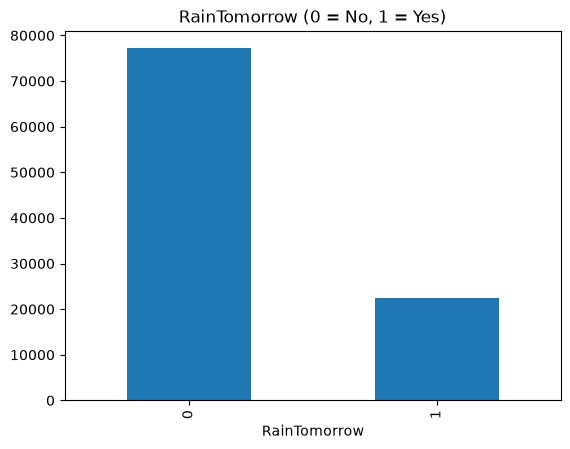

In [11]:
# Create a bar chart showing the RainTomorrow
df['RainTomorrow'].value_counts().plot(kind='bar', title='RainTomorrow (0 = No, 1 = Yes)')
plt.show()

In [12]:
# Show the missing values per column
df.isnull().sum()

row ID               0
Location             0
MinTemp            443
MaxTemp            230
Rainfall           979
Evaporation      42531
Sunshine         47317
WindGustDir       6521
WindGustSpeed     6480
WindDir9am        7006
WindDir3pm        2648
WindSpeed9am       935
WindSpeed3pm      1835
Humidity9am       1233
Humidity3pm       2506
Pressure9am       9748
Pressure3pm       9736
Cloud9am         37572
Cloud3pm         40002
Temp9am            614
Temp3pm           1904
RainToday          979
RainTomorrow         0
dtype: int64

## 2. Data Preparation & Feature Selection

In [13]:
df = df.drop(columns=['row ID', 'Location', 'Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm'])
df.shape

(99516, 17)

In [14]:
# RainToday is a feature -- drop rows where it's missing, then encode Yes/No as 1/0
df = df.dropna(subset=['RainToday'])
df['RainToday'] = df['RainToday'].map({'Yes': 1, 'No': 0})

df['RainToday'].value_counts()

RainToday
0    76481
1    22056
Name: count, dtype: int64

In [15]:
# RainTomorrow is our label. It is already 0/1 with no missing values.
df['RainTomorrow'].value_counts()

RainTomorrow
0    76664
1    21873
Name: count, dtype: int64

In [16]:
# Impute remaining missing numeric values with the column mean
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

df.isnull().sum().sum()  # should be 0 for numeric columns now

np.int64(15736)

In [17]:
# Select a manageable, meaningful feature set
features = ['MinTemp', 'Rainfall', 'Humidity9am', 'Humidity3pm',
            'Pressure9am', 'Pressure3pm', 'WindGustSpeed', 'RainToday']

X = df[features]
y = df['RainTomorrow']

X.head()

,MinTemp,Rainfall,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,WindGustSpeed,RainToday
0,13.4,0.6,71.0,22.0,1007.7,1007.1,44.0,0
1,7.4,0.0,44.0,25.0,1010.6,1007.8,44.0,0
2,17.5,1.0,82.0,33.0,1010.8,1006.0,41.0,0
3,14.6,0.2,55.0,23.0,1009.2,1005.4,56.0,0
4,7.7,0.0,48.0,19.0,1013.4,1010.1,35.0,0


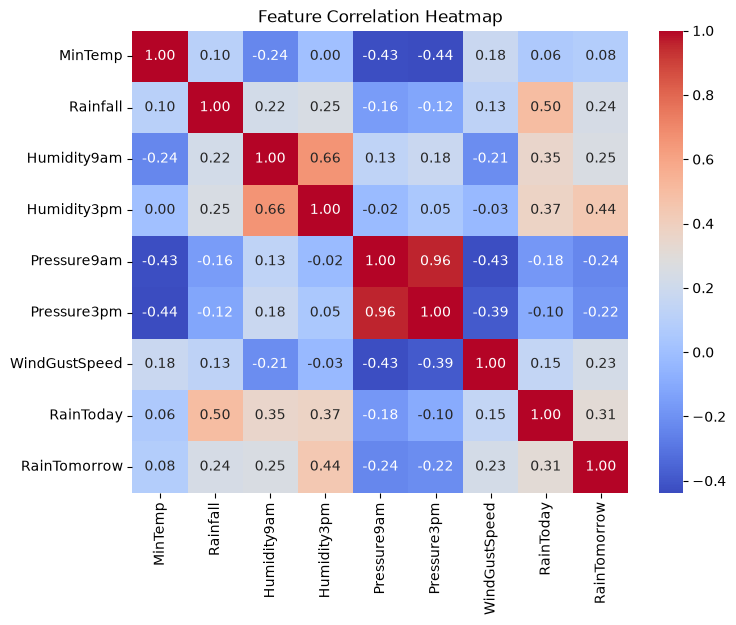

In [18]:
plt.figure(figsize=(8,6))
sns.heatmap(df[features + ['RainTomorrow']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

## 3. Train/Test Split & Model Training

We'll train three models: **Logistic Regression**, **Decision Tree**, and **Random Forest**.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (78829, 8)  Test size: (19708, 8)


### 3.1 Logistic Regression

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

log_preds = log_model.predict(X_test_scaled)
print("Logistic Regression trained.")

Logistic Regression trained.


### 3.2 Decision Tree

In [21]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

tree_preds = tree_model.predict(X_test)
print("Decision Tree trained.")

Decision Tree trained.


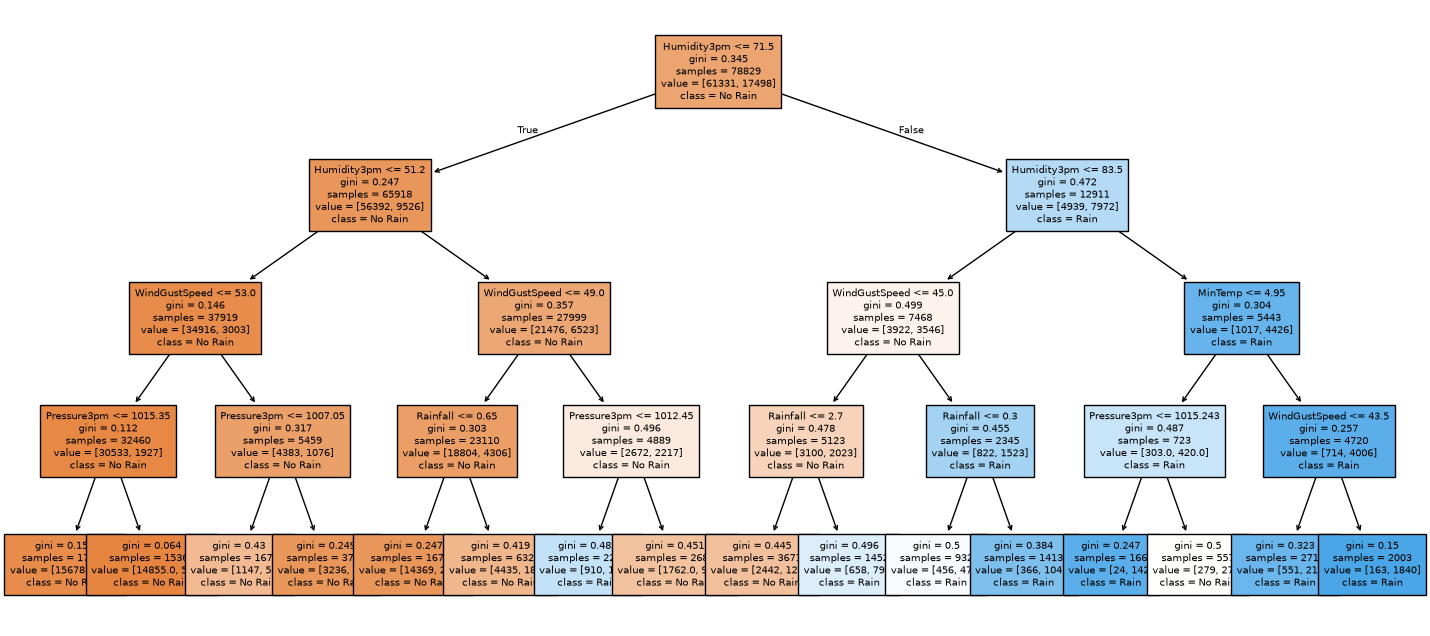

In [22]:
plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=features, class_names=['No Rain', 'Rain'],
          filled=True, fontsize=7)
plt.show()

### 3.3 Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
print("Random Forest trained.")

Random Forest trained.


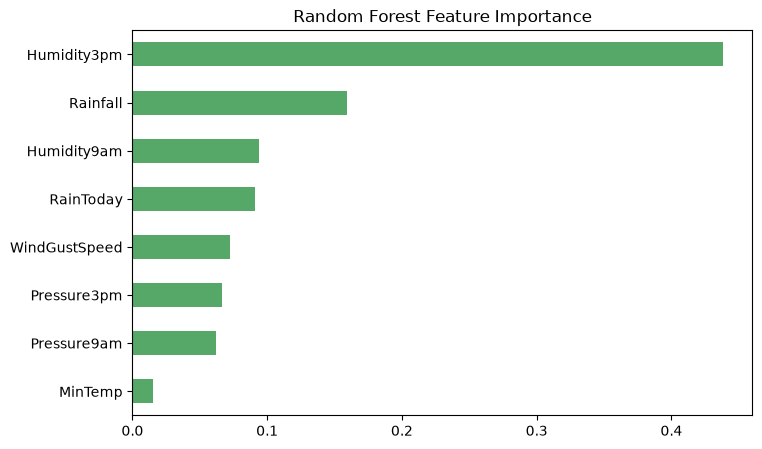

In [24]:
# Feature importance from Random Forest -- nice bridge into "which features matter most"
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importances.plot(kind='barh', color='#55A868')
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

## 4. Evaluation

Comparing Accuracy, Precision, Recall, and F1-score across all three models.

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

models = {
    'Logistic Regression': (log_model, X_train_scaled, X_test_scaled),
    'Decision Tree': (tree_model, X_train, X_test),
    'Random Forest': (rf_model, X_train, X_test),
}
preds = {'Logistic Regression': log_preds, 'Decision Tree': tree_preds, 'Random Forest': rf_preds}

summary_df = pd.DataFrame({
    name: {
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p),
        'Recall': recall_score(y_test, p),
        'F1-score': f1_score(y_test, p),
    }
    for name, p in preds.items()
}).T.round(4)
summary_df

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.8404,0.7161,0.4658,0.5645
Decision Tree,0.8368,0.7105,0.4471,0.5488
Random Forest,0.8426,0.7776,0.4075,0.5348


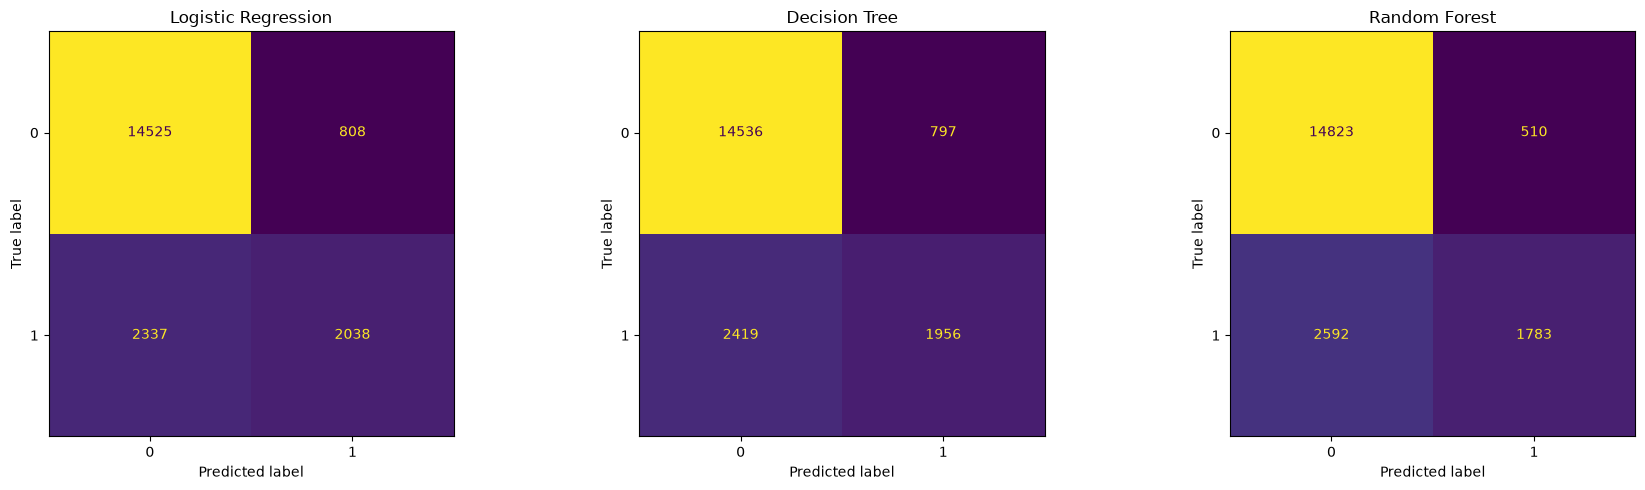

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 5. Overfitting & Model Improvement

Comparing training accuracy vs. test accuracy to check for overfitting.

In [ ]:
overfit_df = pd.DataFrame({
    name: {
        'Train Accuracy': accuracy_score(y_train, model.predict(xtr)),
        'Test Accuracy': accuracy_score(y_test, model.predict(xte)),
    }
    for name, (model, xtr, xte) in models.items()
}).T
overfit_df['Gap'] = overfit_df['Train Accuracy'] - overfit_df['Test Accuracy']
overfit_df.round(4)

In [ ]:
# A deeper tree memorizes the training data: train accuracy keeps rising, test accuracy does not.
depths = range(1, 21)
train_scores, test_scores = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))

plt.figure(figsize=(9, 6))
plt.plot(depths, train_scores, marker='o', label='Train Accuracy')
plt.plot(depths, test_scores, marker='o', label='Test Accuracy')
plt.xlabel("Tree Depth (max_depth)")
plt.ylabel("Accuracy")
plt.title("Overfitting Curve: Train vs. Test Accuracy by Tree Depth")
plt.legend()
plt.show()

## 6. Try It Yourself

A few quick experiments to run live or leave as a takeaway:

1. Swap in a different feature set (e.g., add `WindGustDir` with one-hot encoding) — does performance change?
2. Try `RandomForestClassifier(n_estimators=200)` — does more trees help?
3. Try `class_weight='balanced'` in Logistic Regression or Random Forest — does it change precision/recall trade-offs?
4. Use `GridSearchCV` to tune `max_depth` automatically instead of guessing.

---
### Resources
- Dataset: https://www.kaggle.com/datasets/arunavakrchakraborty/australia-weather-data
- scikit-learn docs: https://scikit-learn.org/stable/documentation.html

*End of notebook — thank you for joining Weather-Weather Lang!* 🌦️